In [2]:
from pathlib import Path
import pandas as pd
from PIL import Image
from weavingtools.annotation_tools import *
from weavingtools.linkage_tools import *
from weavingtools.embedding_tools import *
import seaborn as sns
import numpy as np
sns.set_theme()

In [3]:
collection_df = pd.read_csv('data/heritage_weaver_data.csv')
collection_df  = collection_df[~collection_df['name'].isna()].reset_index(drop=True)
collection_df.shape


(28400, 12)

In [4]:
collection_df.collection.value_counts()

collection
smg    26914
nms     1486
Name: count, dtype: int64

In [5]:
def extract_root_noun_and_adjectives(text: str) -> Tuple[str, List[str]]:
    """
    Extract the root noun and its dependent adjectives from a given text.

    Parameters:
    text (str): The input text.

    Returns:
    Tuple[str, List[str]]: A tuple containing the root noun and a list of its dependent adjectives.
    """
    doc = nlp(text)

    if len(doc) == 1:
        return doc[0].lemma_
    root_noun = ''
    quantifiers = []

    for token in doc:
        #print(token.text, token.dep_, token.pos_)
        if token.dep_ == 'ROOT' and token.pos_ in ['NOUN', 'PROPN']:
            root_noun = token.lemma_
            # for child in token.children:
            #     if (child.dep_ == 'amod' and child.pos_ == 'ADJ') or(child.dep_ == 'compound' and child.pos_ == 'NOUN'):
            #         quantifiers.append(child.lemma_)
            # break
        
    if root_noun == '':
        for token in doc:
            if token.pos_ in ['NOUN', 'PROPN']:
                root_noun = token.lemma_
                # for child in token.children:
                #     if (child.dep_ == 'amod' and child.pos_ == 'ADJ') or(child.dep_ == 'compound' and child.pos_ == 'NOUN'):
                #         quantifiers.append(child.lemma_)
                # break


    return  root_noun.lower()

# Example usage
text = "specimen"
output = extract_root_noun_and_adjectives(text)
output

''

In [6]:
collection_df[collection_df.name.str.match(r'specimen|model|representation|sample')].name.unique()

array(['specimen', 'model', 'models', 'sample',
       'model of pile cross cutting machine; finishing; carpet making; pile cutting; textile finishing',
       'model - representation', 'samples', 'sample box',
       'sample of copper plated aluminium.', 'model (representation)',
       'specimens', 'sample book', 'model - rope drive',
       'model steam engine', 'models (representations)',
       'model transformer', 'model vertical diesel engine',
       'sample dunlop rubber colour chart',
       'model beam engine; engine; model; steam',
       'model lancashire boiler', 'model generator',
       'model (representations)', 'model coupling', 'sample 373',
       'model set of drawers',
       'model to show knitting process; automatic knitting; hose making; knitters; knitting frame; stocking knitting',
       'model-spur wheel', 'sample, mineral', 'model pit prop',
       'model carpet loom; rug making; weaving', 'sample 315',
       'model diesel engine',
       'model hand loom;

In [7]:
import spacy
from tqdm import tqdm
tqdm.pandas()
nlp = spacy.load("en_core_web_lg")

def extract_head_nouns(text: str) -> List[str]:
    #text = text.replace('/ model', '').replace(', model', '').replace('- model', '')
    #doc = nlp(text)
    #head_nouns = [token.lemma_ for token in doc if token.dep_ == 'ROOT' and token.pos_ in ['NOUN','PROPN']]
    quantifiers, root_noun = extract_root_noun_and_adjectives(text)
    return quantifiers, root_noun

#collection_df[['quantifiers','noun_phrases']] = collection_df['name'].progress_apply(extract_head_nouns)
#collection_df['quantifiers'], collection_df['root_noun'] = list(zip(*collection_df['name'].progress_apply(extract_root_noun_and_adjectives)))
collection_df['root_noun'] = collection_df['name'].progress_apply(extract_root_noun_and_adjectives)

100%|██████████| 28400/28400 [01:05<00:00, 435.89it/s]


In [8]:
with open('data/eval/eval_ids.txt','r') as f:
    eval_ids = f.read().splitlines()
print(len(eval_ids))

2172


In [9]:
eval_df = collection_df[collection_df['record_id'].isin(eval_ids)].reset_index(drop=True)
eval_df.shape

(1922, 13)

In [88]:
n_candidates = 0 # 5 or 10
target_col = 'root_noun' # 'root_noun' or 'name'

def add_names(row, df, column): # first_noun_phrase or name
    names = [row[column]]
    while len(names) < n_candidates:
        name = df[column].sample().values[0]
        if name not in names:
            names.append(name)

    return names

if n_candidates > 0:
    eval_df['candidate_labels'] = eval_df.apply(lambda x: add_names(x, collection_df, target_col), axis=1)
else:
    eval_df['candidate_labels'] = list(collection_df[target_col].unique())

Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/d2/ydv0grbd38985h6_95t0vdjw0000gp/T/ipykernel_17051/3202076982.py", line 16, in <module>
    eval_df['candidate_labels'] = list(collection_df[target_col].unique())
  File "/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/pandas/core/frame.py", line 3612, in __setitem__
  File "/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/pandas/core/frame.py", line 3784, in _set_item
    copy : bool, default False
  File "/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/pandas/core/frame.py", line 4509, in _sanitize_column
    )
  File "/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/pandas/core/common.py", line 531, in require_length

In [87]:
 list(collection_df[target_col].unique())

['cassette',
 'fuel',
 'recorder',
 'shade',
 'component',
 'lamp',
 'push',
 'vase',
 'box',
 'sample',
 'meter',
 'block',
 'whorl',
 'seal',
 'check',
 'rule',
 'die',
 'sign',
 'bell',
 'pump',
 'instrument',
 'badge',
 'chock',
 'pot',
 'glove',
 'unit',
 'packing',
 'valve',
 'wattmeter',
 'cover',
 'gauge',
 'tally',
 'plate',
 'pestle',
 'hammer',
 'wedge',
 'board',
 'stencil',
 'tool',
 'stress',
 'mask',
 'heater',
 'axe',
 'stick',
 'payphone',
 'brake',
 'tub',
 'kettle',
 'chisel',
 'tong',
 'bobbin',
 'bit',
 'boot',
 'demonstrator',
 'key',
 'mould',
 'sampler',
 'cable',
 'plaque',
 'toy',
 'helmet',
 'micrometer',
 'switch',
 'fuse',
 'tape',
 'motor',
 'cutter',
 'joint',
 'case',
 'iron',
 'silk',
 'fascia',
 'chain',
 'doll',
 'trainer',
 'beam',
 'head',
 'anenometer',
 'hook',
 'tap',
 'equipment',
 'roller',
 'pick',
 'nail',
 'volume',
 'gasolier',
 'container',
 'machine',
 'filament',
 'adaptor',
 'bracket',
 'material',
 'bob',
 'work',
 'bangle',
 'specimen

In [92]:
print(eval_df[['name','root_noun','candidate_labels']].sample(5).to_latex())

\begin{tabular}{llll}
\toprule
{} &             name &  root\_noun &                                   candidate\_labels \\
\midrule
785  &         dye rack &       rack &  [dye rack, galvanometer, buttons, mineral, spe... \\
392  &         specimen &   specimen &  [specimen, ammeter, washing tint, badge, carbo... \\
988  &  radar equipment &  equipment &  [radar equipment, mimic board tile, pipe, tele... \\
635  &     water filter &     filter &  [water filter, wires; slide rules; slide rules... \\
1012 &         specimen &   specimen &  [specimen, telegraph instrument, black-and-whi... \\
\bottomrule
\end{tabular}



In [93]:
from transformers import pipeline
from PIL import Image
from tqdm import tqdm
import requests
tqdm.pandas()

def get_predictions(row):
    image = Image.open(row['img_path'])
    predictions = detector(image, candidate_labels=row['candidate_labels'], max_length=512)
    return predictions

for ext, checkpoint in { 
                    'ft-best':'Kaspar/siglip-heritage-weaver-best',
                    'ft-last':'Kaspar/siglip-heritage-weaver-last',
                    'base':'google/siglip-base-patch16-224'
                    }.items():
    detector = pipeline(model=checkpoint, task="zero-shot-image-classification")
    eval_df[f'predictions_{ext}'] = eval_df.progress_apply(get_predictions, axis=1)


100%|██████████| 1922/1922 [08:02<00:00,  3.98it/s]


In [94]:
def get_label(predictions):
    label, max_score = '', 0
    for pred in predictions:
        if pred['score'] > max_score:
            label = pred['label']
            max_score = pred['score']
    return label

for ext in ['base','ft-last','ft-best']:
    eval_df[f'label_{ext}'] = eval_df[f'predictions_{ext}'].apply(lambda x: get_label(x))

In [95]:
#eval_df_red = eval_df[~eval_df['root_noun'].isin(['model','specimen','component','sample'])]

In [96]:
all_labels = set([l for i,row in eval_df['candidate_labels'].iteritems() for l in row])
lab2idx = {l:i for i,l in enumerate(sorted(all_labels))}

In [97]:
for ext in ['base','ft-last','ft-best']:
    eval_df[f'prediction_{ext}'] = eval_df[f'label_{ext}'] == eval_df[target_col] #root_noun | name
    print(ext, ' ',round(eval_df[f'prediction_{ext}'].mean(),4))

base   0.7976
ft-last   0.9402
ft-best   0.9433


In [98]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, f1_score
from collections import defaultdict
results = defaultdict(dict)
for ext in ['base','ft-last','ft-best']:
    #eval_df[f'prediction_{ext}'] = eval_df[f'label_{ext}'] == eval_df['root_noun'] #root_noun | name
    eval_df['pred'] = eval_df[f'label_{ext}'].replace(lab2idx)
    eval_df['true'] = eval_df[target_col].replace(lab2idx)
    results[ext]['accuracy'] = accuracy_score(eval_df['pred'] , eval_df['true'])
    results[ext]['precision'] = precision_score(eval_df['pred'] , eval_df['true'], average='weighted')
    results[ext]['f1'] = f1_score(eval_df['pred'] , eval_df['true'], average='weighted')
    

/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_

In [99]:

results = defaultdict(dict)
for ext in ['base','ft-last','ft-best']:
    eval_df_red = eval_df[~eval_df['root_noun'].isin(['specimen','sample','model','photograph'])].reset_index(drop=True)
    #eval_df[f'prediction_{ext}'] = eval_df[f'label_{ext}'] == eval_df['root_noun'] #root_noun | name
    eval_df_red['pred'] = eval_df_red[f'label_{ext}'].replace(lab2idx)
    eval_df_red['true'] = eval_df_red[target_col].replace(lab2idx)
    results[ext]['accuracy'] = accuracy_score(eval_df_red['pred'] , eval_df_red['true'])
    results[ext]['precision'] = precision_score(eval_df_red['pred'] , eval_df_red['true'], average='weighted')
    results[ext]['f1'] = f1_score(eval_df_red['pred'] , eval_df_red['true'], average='weighted')
    

/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_

In [100]:
res_df = pd.DataFrame(results)
res_df = res_df.round(3).T
res_df['target_col'] = target_col
res_df['n_candidates'] = n_candidates
print(res_df[['target_col' , 'n_candidates' ,'accuracy', 'precision','f1']].to_latex())

\begin{tabular}{llrrrr}
\toprule
{} & target\_col &  n\_candidates &  accuracy &  precision &     f1 \\
\midrule
base    &       name &             5 &     0.779 &      0.781 &  0.769 \\
ft-last &       name &             5 &     0.927 &      0.938 &  0.928 \\
ft-best &       name &             5 &     0.932 &      0.943 &  0.934 \\
\bottomrule
\end{tabular}



In [85]:
#top_objects = list(eval_df['root_noun'].value_counts()[:25].index)
top_objects = list(eval_df['root_noun'].value_counts()[:30].index)
print(top_objects)

['specimen', 'lamp', 'block', 'tool', 'model', 'meter', 'valve', 'receiver', 'thermometer', 'sample', 'tile', 'photograph', 'cable', 'radio', 'tube', 'button', 'plane', 'transmitter', 'component', 'equipment', 'machine', 'engine', 'telephone', 'box', 'handset', 'container', 'sign', 'bulb', 'substitute', 'part']


<AxesSubplot:>

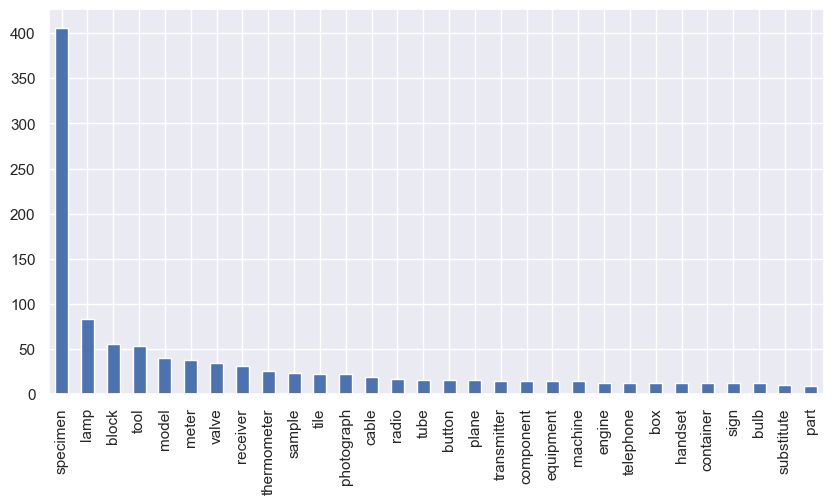

In [86]:
eval_df['root_noun'].value_counts()[:30].plot(kind='bar', figsize=(10,5))

In [87]:
mean_df = eval_df[eval_df.root_noun.isin(top_objects)
        ].groupby('root_noun'
                  )[['prediction_base','prediction_ft-last','prediction_ft-best']].mean()#.plot(kind='bar',figsize=(20,5))

<AxesSubplot:xlabel='root_noun'>

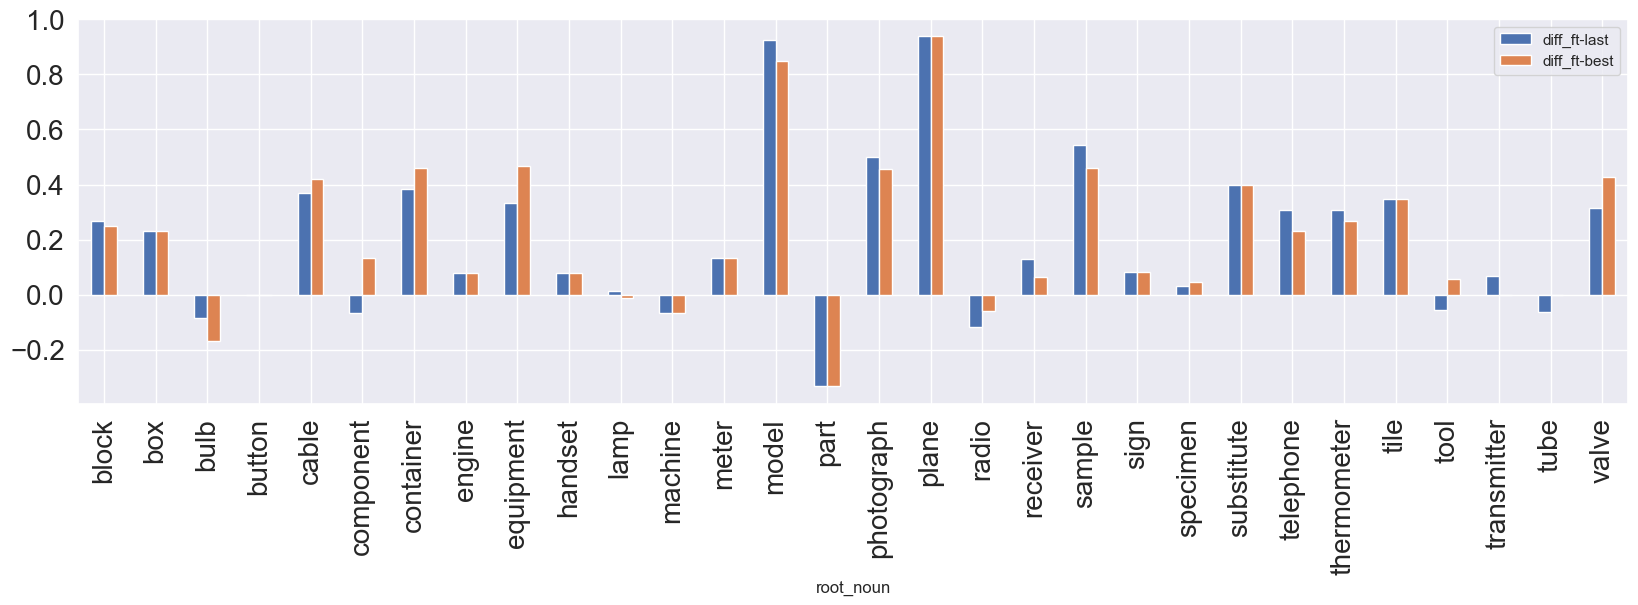

In [88]:
mean_df['diff_ft-best'] = mean_df['prediction_ft-best'] - mean_df['prediction_base']
mean_df['diff_ft-last'] = mean_df['prediction_ft-last'] - mean_df['prediction_base']
mean_df[['diff_ft-last','diff_ft-best']].plot(kind='bar',figsize=(20,5), fontsize=20)

In [81]:
(eval_df['label_ft-best'] == eval_df['root_noun']).mean()

0.8798126951092612

In [82]:
(eval_df['label_ft-last'] == eval_df['root_noun']).mean()

0.8792924037460979

## Retrieval

In [10]:
collection_db = load_db("hw-08-10",'heritage-weaver-base','google/siglip-base-patch16-224')
collection_db_ft_last = load_db("hw-08-10",'heritage-weaver-ft-last','Kaspar/siglip-heritage-weaver-last')
collection_db_ft_best = load_db("hw-08-10",'heritage-weaver-ft-best','Kaspar/siglip-heritage-weaver-best')

In [11]:
from sentence_transformers import SentenceTransformer


model = SentenceTransformer("all-MiniLM-L6-v2")


/Users/kasparbeelen/anaconda3/envs/heritageweaver/lib/python3.9/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [12]:
from scipy.spatial.distance import cosine

def cosine_distances(A, v):
    """
    Compute the cosine distance of each row in matrix A to vector v.

    Parameters:
    A (np.ndarray): A 2D numpy array (matrix).
    v (np.ndarray): A 1D numpy array (vector).

    Returns:
    np.ndarray: A 1D numpy array containing the cosine distances.
    """
    return np.array([cosine(row, np.array(v).reshape(-1)) for row in A])




In [13]:
results_all =[]
for ext, db in [('base',collection_db),('ft-last',collection_db_ft_last),('ft-best',collection_db_ft_best)]:
    for idx in tqdm(range(eval_df.shape[0])): #
       
        query_img = eval_df.img_path.iloc[idx]
        query_name = eval_df.name.iloc[idx]
        results = db.query(query_uris=[query_img], n_results=10)

        names = [o.get('name','') for o in results['metadatas'][0]]
        names = [n for n in names if n != '']
        embeddings = model.encode(names)
        query_embedding = model.encode([query_name])

        distances = cosine_distances(embeddings, query_embedding)
        results_all.append([ext,query_name,distances])




 57%|█████▋    | 1096/1922 [02:27<01:51,  7.41it/s]
[E thread_pool.cpp:109] Exception in thread pool task: mutex lock failed: Invalid argument


KeyboardInterrupt: 

In [14]:
eval_df.columns

Index(['Unnamed: 0', 'record_id', 'name', 'description', 'category',
       'taxonomy', 'img_loc', 'img_name', 'img_path', 'downloaded', 'img_url',
       'collection', 'root_noun'],
      dtype='object')

In [42]:
# cross collections search
colldict = {'smg':'nms',    
            'nms':'smg'}   

results_all =[]
for ext, db in [('base',collection_db),('ft-last',collection_db_ft_last),('ft-best',collection_db_ft_best)]:
    for idx in tqdm(range(eval_df.shape[0])): #
       
        query_img = eval_df.img_path.iloc[idx]
        query_collection = eval_df.collection.iloc[idx]
        query_name = eval_df.name.iloc[idx]
        results = db.query(
                        query_uris=[query_img], 
                        n_results=20, 
                        where = {
                                "$and": [
                                    {
                                        "modality": {
                                            "$eq": "image"
                                        }
                                    },
                                    {
                                        "collection": {
                                            "$eq" : colldict[query_collection]
                                        }
                                    }
                                ]
                            })

        names = [o.get('name','') for o in results['metadatas'][0]]
        names = [n for n in names if n != '']
        embeddings = model.encode(names)
        query_embedding = model.encode([query_name])

        distances = cosine_distances(embeddings, query_embedding)
        results_all.append([ext,query_name,distances])




100%|██████████| 1922/1922 [20:35<00:00,  1.56it/s]


In [43]:
results_df = pd.DataFrame(results_all, columns=['model','query_name','distances'])
threshold = 0.05
results_df['similar'] = results_df['distances'].apply(lambda x: sum(x < threshold))

In [44]:
results_df['root_noun'] =  results_df['query_name'].progress_apply(extract_root_noun_and_adjectives)
results_df['root_noun'] = results_df['root_noun'].str.lower()

100%|██████████| 5766/5766 [00:13<00:00, 426.78it/s]


In [45]:
by_noun = results_df.groupby(['model','root_noun'])['similar'].mean().unstack().T

In [46]:
(by_noun['ft-best'] - by_noun['base']).sort_values()

root_noun
transistor    -3.000000
ratemeter     -0.500000
radio          0.000000
racket         0.000000
rack           0.000000
                 ...   
stereoscope    1.000000
generator      1.000000
cable          1.052632
telephone      1.230769
wattmeter      2.000000
Length: 455, dtype: float64

In [48]:
results_df.groupby('model')['similar'].std().round(3)

model
base       0.921
ft-best    1.116
ft-last    1.116
Name: similar, dtype: float64

model
base       AxesSubplot(0.125,0.11;0.775x0.77)
ft-best    AxesSubplot(0.125,0.11;0.775x0.77)
ft-last    AxesSubplot(0.125,0.11;0.775x0.77)
Name: similar, dtype: object

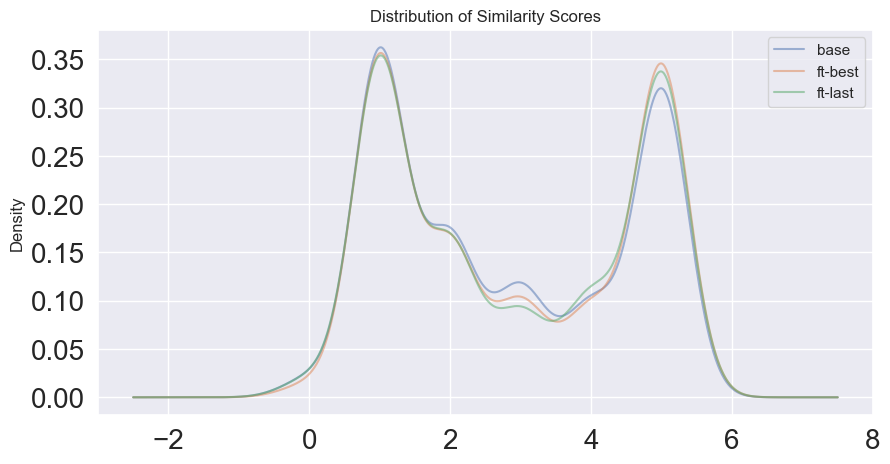

In [106]:
results_df.groupby('model')['similar'].plot(kind='density', figsize=(10,5), title='Distribution of Similarity Scores', fontsize=20, alpha=0.5, legend=True)

In [108]:
eval_df.iloc[0]

Unnamed: 0                                                            11
record_id                                                       co520633
name                                                                vase
description            Earthenware vase, marked `Como\1962'. Italian....
category                                             Domestic Appliances
taxonomy                                                             NaN
img_loc                                   331/290/medium_SMG00179605.jpg
img_name                                  331|290|medium_SMG00179605.jpg
img_path                         smg_imgs/331|290|medium_SMG00179605.jpg
downloaded                                                          True
img_url                https://coimages.sciencemuseumgroup.org.uk/331...
collection                                                           smg
root_noun                                                           vase
candidate_labels       [vase, touchstone, mobile te

In [109]:
results['metadatas']

[[{'collection': 'smg',
   'img_path': 'smg_imgs/331|290|medium_SMG00179605.jpg',
   'img_url': 'https://coimages.sciencemuseumgroup.org.uk/331/290/medium_smg00179605.jpg',
   'modality': 'image',
   'name': 'vase',
   'record_id': 'co520633'},
  {'collection': 'smg',
   'img_path': 'smg_imgs/56|324|medium_1980_1703__0001_.jpg',
   'img_url': 'https://coimages.sciencemuseumgroup.org.uk/56/324/medium_1980_1703__0001_.jpg',
   'modality': 'image',
   'name': 'vessels',
   'record_id': 'co68033'},
  {'collection': 'smg',
   'img_path': 'smg_imgs/56|326|medium_1980_1704.jpg',
   'img_url': 'https://coimages.sciencemuseumgroup.org.uk/56/326/medium_1980_1704.jpg',
   'modality': 'image',
   'name': 'vessels',
   'record_id': 'co68034'},
  {'collection': 'smg',
   'img_path': 'smg_imgs/450|909|medium_SMG00227416.jpg',
   'img_url': 'https://coimages.sciencemuseumgroup.org.uk/450/909/medium_smg00227416.jpg',
   'modality': 'image',
   'name': 'dish',
   'record_id': 'co42654'},
  {'collection'

In [105]:
results_df = pd.DataFrame(results_all, columns=['model','query_name','mean_distance','std_distance'])
#results_df.groupby('model')['mean_distance'].plot(kind='density')
results_df.groupby('model')['mean_distance'].mean()

ValueError: 4 columns passed, passed data had 3 columns

In [63]:
filters ={
            "modality": {
                "$eq": "image"
            }
        }

results_all =[]
for ext, db in [('base',collection_db),('ft-last',collection_db_ft_last),('ft-best',collection_db_ft_best)]:
    for idx in tqdm(range(eval_df.shape[0])): # eval_df.shape[0]
       
        query_description = eval_df.description.iloc[idx]
        query_name = eval_df.name.iloc[idx]
        query_record_id = eval_df.record_id.iloc[idx]
        
        try:
            results = db.query(query_texts=[query_description], where=filters,n_results=10)
        except Exception as e:
            print(e)
            continue

        names = [o.get('name','') for o in results['metadatas'][0]]
        record_ids = [o.get('record_id','') for o in results['metadatas'][0]]
        names = [n for n in names if n != '']
        embeddings = model.encode(names)
        query_embedding = model.encode([query_name])

        distances = cosine_distances(embeddings, query_embedding)
        results_all.append([ext,query_name, query_record_id,distances, record_ids])

results_df = pd.DataFrame(results_all, columns=['model','query_name','record_id','distance','record_ids'])
#results_df.groupby('model')['mean_distance'].plot(kind='density')

  0%|          | 0/1922 [00:00<?, ?it/s]

  1%|▏         | 28/1922 [00:25<28:37,  1.10it/s] 

Cannot return the results in a contigious 2D array. Probably ef or M is too small


  2%|▏         | 30/1922 [00:27<27:17,  1.16it/s]

Cannot return the results in a contigious 2D array. Probably ef or M is too small


...

 88%|████████▊ | 1687/1922 [26:46<02:16,  1.73it/s]

Cannot return the results in a contigious 2D array. Probably ef or M is too small


 88%|████████▊ | 1688/1922 [26:46<02:12,  1.77it/s]

Cannot return the results in a contigious 2D array. Probably ef or M is too small


100%|██████████| 1922/1922 [29:28<00:00,  1.09it/s]


In [67]:
filters ={
            "modality": {
                "$eq": "text"
            }
        }

results_all =[]
for ext, db in [('base',collection_db),('ft-last',collection_db_ft_last),('ft-best',collection_db_ft_best)]:
    for idx in tqdm(range(eval_df.shape[0])): # 

        query_img = eval_df.img_path.iloc[idx]
        query_name = eval_df.name.iloc[idx]
        query_record_id = eval_df.record_id.iloc[idx]
        try:
            results = db.query(query_uris=[query_img], where=filters,n_results=10)
        except Exception as e:
            print(e)
            continue

        names = [o.get('name','') for o in results['metadatas'][0]]
        record_ids = [o.get('record_id','') for o in results['metadatas'][0]]
        names = [n for n in names if n != '']
        embeddings = model.encode(names)
        query_embedding = model.encode([query_name])

        distances = cosine_distances(embeddings, query_embedding)
        results_all.append([ext,query_name, query_record_id,distances, record_ids])

results_df = pd.DataFrame(results_all, columns=['model','query_name','record_id','distance','record_ids'])
#results_df.groupby('model')['mean_distance'].plot(kind='density')

100%|██████████| 1922/1922 [1:08:37<00:00,  2.14s/it]  


In [97]:
results_df['similar'] = results_df['distance'].apply(lambda x: sum(x < 0.05))

In [98]:
results_df.groupby('model')['similar'].mean().round(3)

model
base       2.234
ft-best    3.327
ft-last    3.876
Name: similar, dtype: float64

In [99]:
results_df['found'] = results_df.apply(lambda x: x.record_id in x.record_ids, axis=1)
results_df.groupby('model')['found'].mean().round(3)

model
base       0.122
ft-best    0.054
ft-last    0.109
Name: found, dtype: float64

In [132]:
query_description

'Silk weaving loom with a Jacquard attachment, with a silk scarf on the machine in the process of manufacture, probably made by Joseph Hood of Newmilns, Ayrshire'

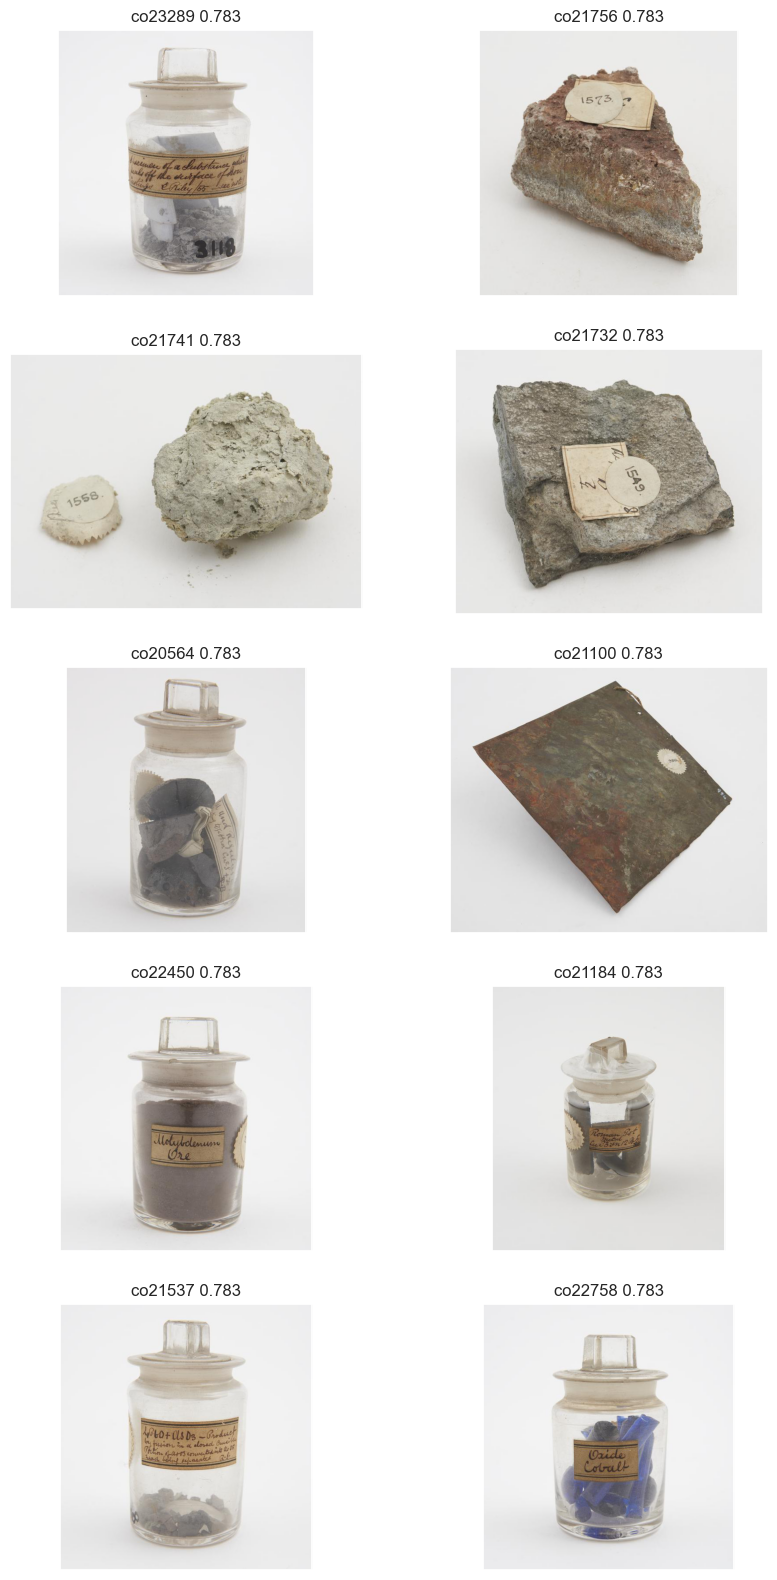

,collection,img_path,img_url,modality,name,record_id,sentence,similarity
0,smg,smg_imgs/390|455|medium_SMG00092700.jpg,https://coimages.sciencemuseumgroup.org.uk/390...,text,specimen,co23289,specimen,0.78327
1,smg,smg_imgs/392|691|medium_SMG00096585.jpg,https://coimages.sciencemuseumgroup.org.uk/392...,text,specimen,co21756,specimen,0.78327
2,smg,smg_imgs/392|709|medium_SMG00096604.jpg,https://coimages.sciencemuseumgroup.org.uk/392...,text,specimen,co21741,specimen,0.78327
3,smg,smg_imgs/392|554|medium_SMG00095139.jpg,https://coimages.sciencemuseumgroup.org.uk/392...,text,specimen,co21732,specimen,0.78327
4,smg,smg_imgs/387|873|medium_SMG00095830.jpg,https://coimages.sciencemuseumgroup.org.uk/387...,text,specimen,co20564,specimen,0.78327
5,smg,smg_imgs/399|628|medium_SMG00001171.jpg,https://coimages.sciencemuseumgroup.org.uk/399...,text,specimen,co21100,specimen,0.78327
6,smg,smg_imgs/387|561|medium_SMG00088069.jpg,https://coimages.sciencemuseumgroup.org.uk/387...,text,specimen,co22450,specimen,0.78327
7,smg,smg_imgs/486|682|medium_SMG00313883.jpg,https://coimages.sciencemuseumgroup.org.uk/486...,text,specimen,co21184,specimen,0.78327
8,smg,smg_imgs/388|37|medium_SMG00098280.jpg,https://coimages.sciencemuseumgroup.org.uk/388...,text,specimen,co21537,specimen,0.78327
9,smg,smg_imgs/390|797|medium_SMG00102175.jpg,https://coimages.sciencemuseumgroup.org.uk/390...,text,specimen,co22758,specimen,0.78327


In [131]:
results = db.query(query_texts=[query_description], n_results=10)
plot_query_results(results)